# Q1B — Digital Detective: *Missing Boundaries*
### Edge Detection via the Sobel Operator

**Objective.** Given a finite two-dimensional discrete image $I(x,y)$, recover the structural
(boundary) information hidden in `missing_boundaries_input.png` by detecting regions where
intensity changes rapidly. We build the theory from first principles (derivatives → gradients →
Sobel operator → 2-D convolution), implement the operator from scratch, validate it against
a trusted library implementation, and then study two practical questions the brief asks us to
address:

1. How does **noise** corrupt the detected boundaries?
2. What role does **smoothing** play before edge extraction, and can **weak edges** be preserved
   without re-introducing excessive noise?

---

## 1. Theory: From Derivatives to Edges

### 1.1 Why derivatives?

An edge is, by definition, a place where the image intensity $I(x,y)$ changes **abruptly** —
the boundary of an object is exactly where pixel values jump from one region's typical
brightness to another's. The mathematical operation that quantifies *rate of change* is the
**derivative**. For a continuous image, the first-order partial derivatives are

$$
\frac{\partial I}{\partial x}, \qquad \frac{\partial I}{\partial y}
$$

Together these form the **gradient vector**:

$$
\nabla I = \left( \frac{\partial I}{\partial x},\; \frac{\partial I}{\partial y} \right)
$$

The gradient points in the direction of steepest intensity increase, and its magnitude tells us
*how fast* the intensity is changing at that point:

$$
\|\nabla I\| = \sqrt{\left(\frac{\partial I}{\partial x}\right)^2 + \left(\frac{\partial I}{\partial y}\right)^2},
\qquad
\theta = \arctan\!\left(\frac{\partial I/\partial y}{\partial I/\partial x}\right)
$$

**Where the gradient magnitude is large, an edge is likely present.** A flat, uniform region
(sky, wall, road surface) has near-zero gradient everywhere; an object boundary produces a
sharp spike. This is the fundamental link between derivatives/gradients and edge detection:
*edges are local maxima of gradient magnitude*.

### 1.2 From continuous to discrete: why a kernel?

Our image $I(x,y)$ is **discrete and finite** — a grid of pixels, not a continuous function — so
we cannot evaluate $\partial I/\partial x$ analytically. Instead we **approximate** the derivative
using finite differences. The simplest approximation is

$$
\frac{\partial I}{\partial x} \approx I(x+1,y) - I(x-1,y)
$$

This is a 1-D, 3-tap filter $[-1, 0, 1]$ applied along rows. Real images are noisy, however, and a
derivative computed from only two neighbouring pixels amplifies that noise badly (differentiation
is a high-pass, noise-amplifying operation). The **Sobel operator** improves on the naive
difference by *combining differentiation in one direction with smoothing in the perpendicular
direction*, which suppresses noise while still detecting the edge.

### 1.3 The Sobel kernels

The Sobel operator separates into a **difference kernel** (detects the gradient) and a
**smoothing kernel** (a discrete approximation of a triangular/Gaussian-like weighting),
combined via an outer product:

$$
\underbrace{\begin{bmatrix}1\\2\\1\end{bmatrix}}_{\text{smooth (Gaussian-like)}}
\;\times\;
\underbrace{\begin{bmatrix}-1 & 0 & 1\end{bmatrix}}_{\text{difference}}
=
\begin{bmatrix}
-1 & 0 & 1\\
-2 & 0 & 2\\
-1 & 0 & 1
\end{bmatrix}
= G_x
$$

and, by symmetry (smoothing in $x$, differencing in $y$):

$$
G_y =
\begin{bmatrix}
-1 & -2 & -1\\
\phantom{-}0 & \phantom{-}0 & \phantom{-}0\\
\phantom{-}1 & \phantom{-}2 & \phantom{-}1
\end{bmatrix}
$$

So $G_x$ estimates $\partial I/\partial x$ (and responds strongly to **vertical** edges, since a
vertical edge produces a horizontal intensity jump), while $G_y$ estimates $\partial I/\partial y$
(responding to **horizontal** edges). This built-in smoothing is exactly why the Sobel filter is
preferred over a bare $[-1,0,1]$ difference: it is *less sensitive to noise* while remaining cheap
to compute (integer coefficients, separable, $3\times3$ support).

### 1.4 2-D convolution

Applying a kernel $K$ to an image $I$ via **2-D convolution** is defined as

$$
(I * K)(x,y) = \sum_{i}\sum_{j} I(x-i,\,y-j)\,K(i,j)
$$

which involves *flipping* the kernel $180°$ before sliding it across the image. In practice, most
image-processing libraries (including OpenCV's `cv2.Sobel` and the Sobel filter as it is
conventionally taught) implement **correlation** instead — sliding the kernel *without* flipping it:

$$
(I \star K)(x,y) = \sum_{i}\sum_{j} I(x+i,\,y+j)\,K(i,j)
$$

For a kernel that is symmetric under $180°$ rotation the two operations coincide; the Sobel kernel
is **anti-symmetric** ($K(i,j) = -K(-i,-j)$), so flipping it merely negates the result (i.e. swaps
which side of an edge is "positive"). Since we take $\sqrt{G_x^2+G_y^2}$ at the end, the sign is
discarded and the **magnitude image is identical either way** — but we verify this explicitly
below, and implement *true* convolution from scratch to be mathematically faithful to the
definition the question asks about, then cross-check against the library's correlation-based
`cv2.Sobel`.

The gradient magnitude image — the final output of the edge detector — is what the question's
Figure 1 shows on the right: a "wireframe" rendering containing only the high-gradient pixels.


---
## 2. Setup

In [ ]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from scipy import ndimage

plt.rcParams['figure.dpi'] = 100
np.set_printoptions(precision=2, suppress=True)

### 2.1 Load the image and convert to grayscale

Edge detection operates on a single intensity channel. The provided RGB photograph is converted
to grayscale using the standard luminance-weighted formula
($0.299R + 0.587G + 0.114B$, as used by `cv2.cvtColor`), since human-perceived structural
boundaries are overwhelmingly carried by luminance rather than colour.

Image shape (H, W): (675, 1200)
Intensity range  : 0.0 - 255.0


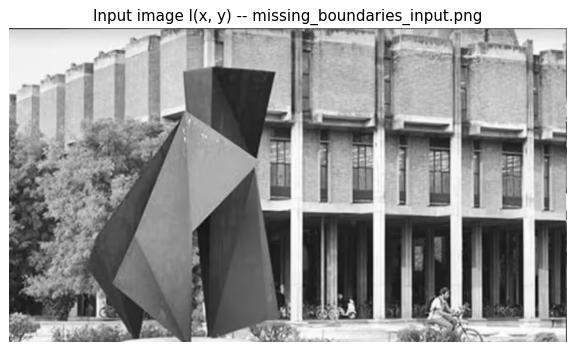

In [ ]:
IMG_PATH = "missing_boundaries_input.png"

img_bgr = cv2.imread(IMG_PATH)
if img_bgr is None:
    raise FileNotFoundError(f"Could not load {IMG_PATH} -- check the file is in the working directory.")

img_gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY).astype(np.float64)

print("Image shape (H, W):", img_gray.shape)
print("Intensity range  :", img_gray.min(), "-", img_gray.max())

plt.figure(figsize=(8,5))
plt.imshow(img_gray, cmap='gray')
plt.title("Input image I(x, y) -- missing_boundaries_input.png")
plt.axis('off')
plt.show()

---
## 3. Implementing the Sobel Operator from Scratch

### 3.1 Define the kernels

In [ ]:
# Sobel kernels (3x3): smoothing in one axis, central differencing in the other
Gx_kernel = np.array([[-1, 0, 1],
                       [-2, 0, 2],
                       [-1, 0, 1]], dtype=np.float64)

Gy_kernel = np.array([[-1, -2, -1],
                       [ 0,  0,  0],
                       [ 1,  2,  1]], dtype=np.float64)

print("Gx kernel (responds to vertical edges):\n", Gx_kernel)
print("\nGy kernel (responds to horizontal edges):\n", Gy_kernel)

Gx kernel (responds to vertical edges):
 [[-1.  0.  1.]
 [-2.  0.  2.]
 [-1.  0.  1.]]

Gy kernel (responds to horizontal edges):
 [[-1. -2. -1.]
 [ 0.  0.  0.]
 [ 1.  2.  1.]]


### 3.2 Manual 2-D convolution

We implement the textbook convolution definition
$\,(I*K)(x,y) = \sum_i\sum_j I(x-i,y-j)K(i,j)\,$ directly: pad the image (zero-padding) so the
kernel can be centred on border pixels, flip the kernel $180°$, then slide-and-multiply-and-sum
over every pixel. This is the "by-hand" version requested by the question; it is intentionally
written with explicit loops for transparency, and is validated against `scipy.ndimage` below
before we switch to the fast, vectorised routine for the rest of the analysis.

In [ ]:
def convolve2d_manual(image: np.ndarray, kernel: np.ndarray) -> np.ndarray:
    """
    True 2-D convolution (kernel flipped 180 degrees) with zero padding.
    Implemented with explicit loops to mirror the mathematical definition:
        (I * K)(x, y) = sum_i sum_j I(x-i, y-j) * K(i, j)
    """
    kh, kw = kernel.shape
    pad_h, pad_w = kh // 2, kw // 2

    flipped_kernel = np.flipud(np.fliplr(kernel))          # convolution flips the kernel
    padded = np.pad(image, ((pad_h, pad_h), (pad_w, pad_w)),
                     mode='constant', constant_values=0)    # zero padding at borders

    H, W = image.shape
    output = np.zeros((H, W), dtype=np.float64)

    for i in range(H):
        for j in range(W):
            region = padded[i:i + kh, j:j + kw]
            output[i, j] = np.sum(region * flipped_kernel)

    return output

### 3.3 Correctness check

Before trusting the manual routine on a $1200\times675$ photograph (which would take a long time
with pure Python loops), we validate it on a small random array against `scipy.ndimage.convolve`,
a well-tested reference implementation of the *same* mathematical convolution.

In [ ]:
rng = np.random.default_rng(0)
test_patch = rng.random((12, 12))

manual_result = convolve2d_manual(test_patch, Gx_kernel)
reference_result = ndimage.convolve(test_patch, Gx_kernel, mode='constant', cval=0.0)

print("Manual convolution matches scipy.ndimage.convolve:",
      np.allclose(manual_result, reference_result))
print("Max absolute difference:", np.max(np.abs(manual_result - reference_result)))

Manual convolution matches scipy.ndimage.convolve: True
Max absolute difference: 8.881784197001252e-16


**Why we don't run the pure-Python manual version on the full photo.** With explicit
double `for` loops, convolving an image with $H\times W \approx 8\times10^5$ pixels takes on the
order of a minute or more in pure Python -- acceptable for demonstrating *correctness* on a small
patch, but not for the repeated experiments (noise levels, smoothing levels, threshold sweeps)
performed later in this notebook. From here on we use `scipy.ndimage`'s compiled, vectorised
convolution/correlation routines, which implement *exactly the same mathematics*, just efficiently.
This is standard practice: write and verify the operation by hand once, then use the optimised
library call for production work.

### 3.4 Convolution vs. correlation -- a practical subtlety

As discussed in Section 1.4, OpenCV's `cv2.Sobel` (and most "Sobel filter" implementations in
practice) perform **correlation**, not flipped convolution. We confirm this and show that it does
not change our final gradient-magnitude result, because the Sobel kernel's anti-symmetry only
flips the *sign* of $G_x, G_y$, which is removed by squaring.

In [ ]:
Gx_conv = ndimage.convolve(img_gray, Gx_kernel, mode='reflect')     # true convolution (flips kernel)
Gx_corr = ndimage.correlate(img_gray, Gx_kernel, mode='reflect')    # correlation (no flip) -- what cv2.Sobel does
Gx_cv2  = cv2.Sobel(img_gray, cv2.CV_64F, 1, 0, ksize=3, borderType=cv2.BORDER_REFLECT)

print("correlate() matches cv2.Sobel exactly :", np.allclose(Gx_corr, Gx_cv2))
print("convolve() == -correlate() (sign flip):", np.allclose(Gx_conv, -Gx_corr))
print("|Gx| identical either way              :", np.allclose(np.abs(Gx_conv), np.abs(Gx_corr)))

correlate() matches cv2.Sobel exactly : True
convolve() == -correlate() (sign flip): True
|Gx| identical either way              : True


---
## 4. Revealing the Hidden Boundaries

We now apply the Sobel kernels to the full image, compute the gradient magnitude
$\|\nabla I\| = \sqrt{G_x^2 + G_y^2}$ and direction $\theta=\arctan(G_y/G_x)$, and visualise each
stage. `mode='reflect'` is used at the borders (mirroring pixels rather than zero-padding) so that
the outermost rows/columns of the photo don't generate a spurious bright frame.

In [ ]:
def sobel_filter(image: np.ndarray):
    """Apply the Sobel operator and return (Gx, Gy, magnitude, direction_radians)."""
    Gx = ndimage.convolve(image, Gx_kernel, mode='reflect')
    Gy = ndimage.convolve(image, Gy_kernel, mode='reflect')
    magnitude = np.sqrt(Gx**2 + Gy**2)
    direction = np.arctan2(Gy, Gx)
    return Gx, Gy, magnitude, direction

Gx, Gy, magnitude, direction = sobel_filter(img_gray)

print("Gradient magnitude range:", magnitude.min(), "to", magnitude.max())

Gradient magnitude range: 0.0 to 671.0365116742903


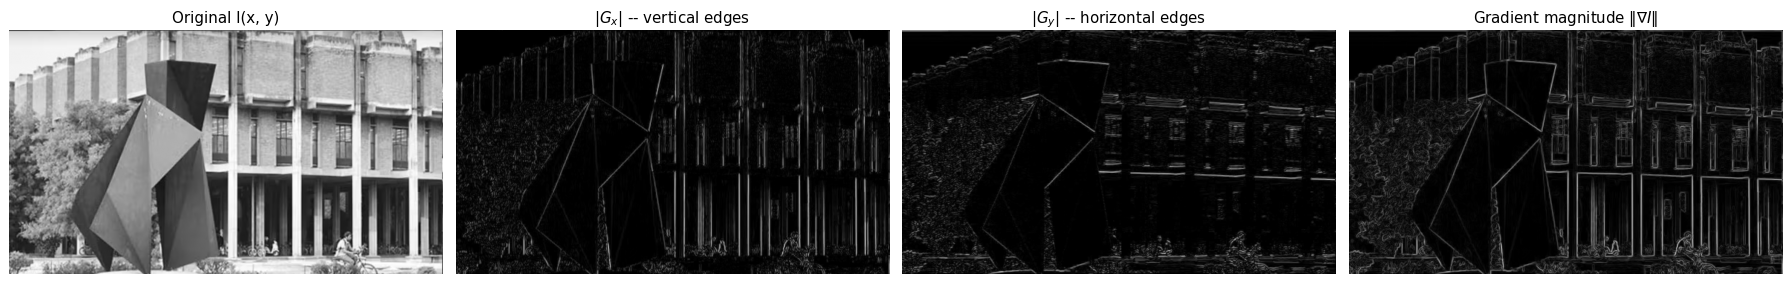

In [ ]:
fig, axs = plt.subplots(1, 4, figsize=(20, 6))

axs[0].imshow(img_gray, cmap='gray')
axs[0].set_title("Original I(x, y)")

axs[1].imshow(np.abs(Gx), cmap='gray')
axs[1].set_title(r"$|G_x|$ -- vertical edges")

axs[2].imshow(np.abs(Gy), cmap='gray')
axs[2].set_title(r"$|G_y|$ -- horizontal edges")

axs[3].imshow(magnitude, cmap='gray')
axs[3].set_title(r"Gradient magnitude $\|\nabla I\|$")

for a in axs:
    a.axis('off')
plt.tight_layout()
plt.show()

**Observation.** $G_x$ lights up wherever there are *vertical* edges (the building's vertical
columns, the sculpture's near-vertical facets) because a vertical edge produces a sharp change as
we scan *horizontally* across it. $G_y$ lights up on *horizontal* edges (window ledges, roofline,
horizon) for the symmetric reason. The combined magnitude map recovers essentially the same
"wireframe" structure shown in Figure 1 of the question: building facade grid, window mullions,
the angular steel sculpture, and the silhouettes of the cyclist and pedestrians -- all without any
colour or texture information, purely from *where intensity changes fastest*.

A binary/thresholded version makes the wireframe analogy with Figure 1 explicit:

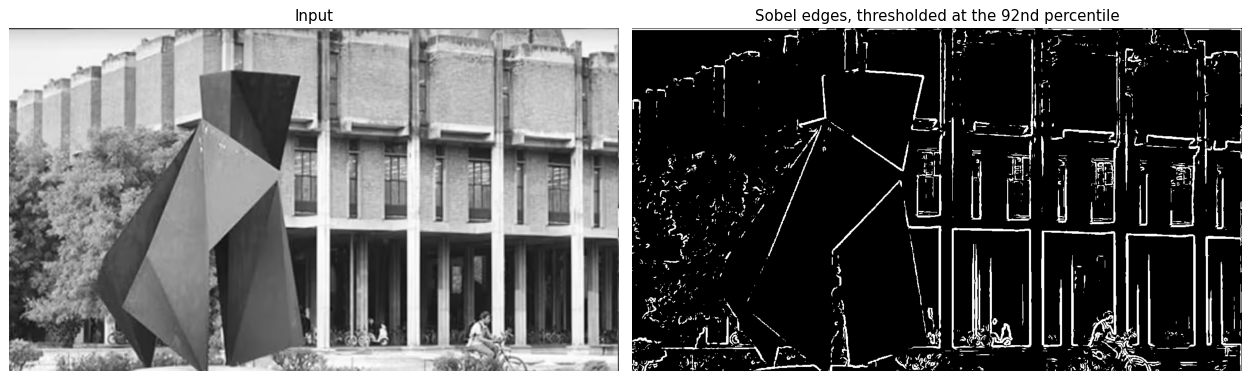

In [ ]:
# Normalise magnitude to 0-255 and binarise at a fixed percentile threshold for display
mag_norm = (magnitude / magnitude.max() * 255).astype(np.uint8)
edge_threshold = np.percentile(mag_norm, 92)
binary_edges = (mag_norm > edge_threshold).astype(np.uint8) * 255

fig, axs = plt.subplots(1, 2, figsize=(14, 7))
axs[0].imshow(img_gray, cmap='gray')
axs[0].set_title("Input")
axs[1].imshow(binary_edges, cmap='gray')
axs[1].set_title(f"Sobel edges, thresholded at the 92nd percentile")
for a in axs:
    a.axis('off')
plt.tight_layout()
plt.show()

---
## 5. How Does Noise Affect the Detected Boundaries?

Section 1 noted that differentiation is a **high-pass operation**: it amplifies high-frequency
content. Real-world noise (sensor noise, quantisation, compression artefacts) is itself
high-frequency, so a derivative-based edge detector amplifies noise *along with* genuine edges.
We simulate this by adding zero-mean Gaussian noise $\mathcal{N}(0,\sigma^2)$ to the image and
re-running the Sobel detector.

In [ ]:
def add_gaussian_noise(image: np.ndarray, sigma: float, seed: int = 42) -> np.ndarray:
    rng = np.random.default_rng(seed)
    noisy = image + rng.normal(0, sigma, image.shape)
    return np.clip(noisy, 0, 255)

noise_sigma = 25.0
img_noisy = add_gaussian_noise(img_gray, noise_sigma)

_, _, mag_clean, _ = sobel_filter(img_gray)
_, _, mag_noisy, _ = sobel_filter(img_noisy)

print(f"Clean  -- gradient magnitude: mean={mag_clean.mean():.2f}, std={mag_clean.std():.2f}, max={mag_clean.max():.1f}")
print(f"Noisy  -- gradient magnitude: mean={mag_noisy.mean():.2f}, std={mag_noisy.std():.2f}, max={mag_noisy.max():.1f}")

Clean  -- gradient magnitude: mean=51.81, std=68.09, max=671.0
Noisy  -- gradient magnitude: mean=124.28, std=76.19, max=841.5


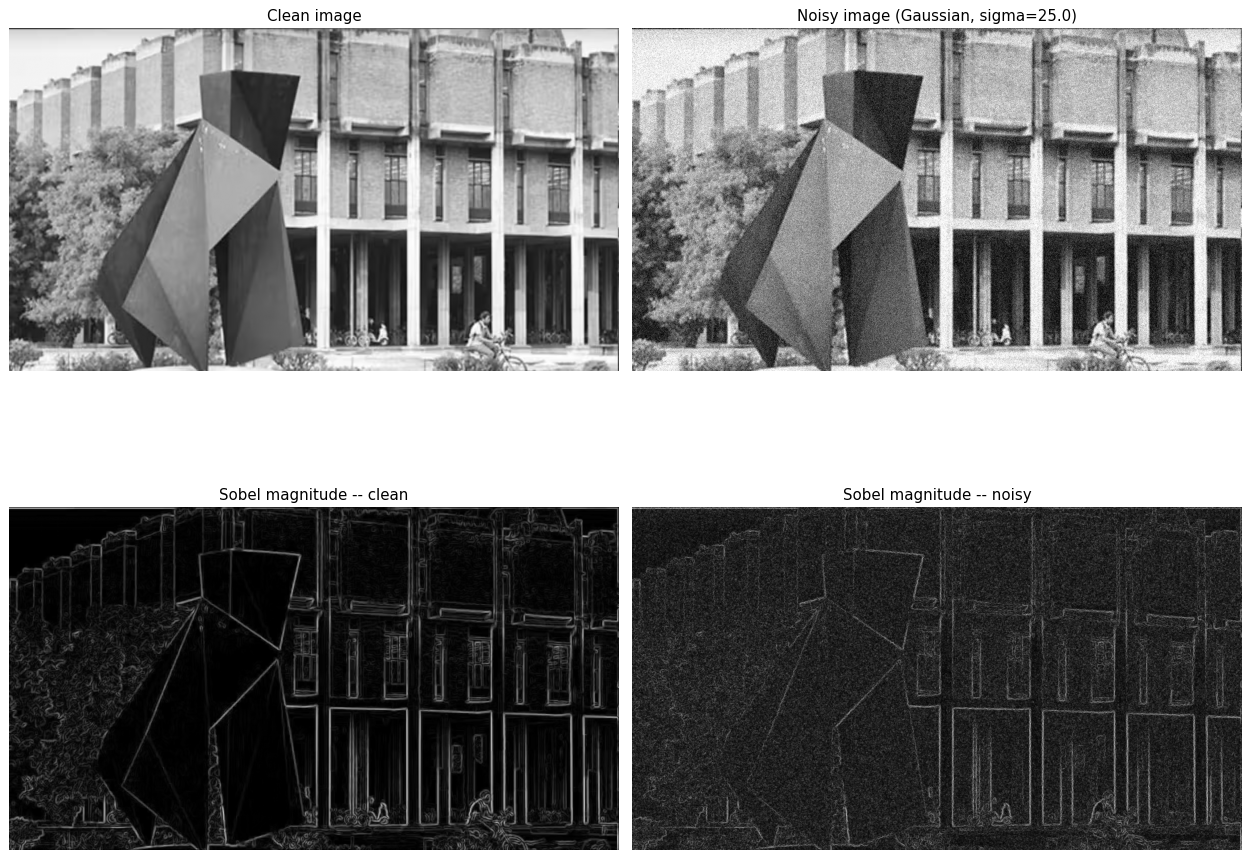

In [ ]:
fig, axs = plt.subplots(2, 2, figsize=(14, 12))

axs[0,0].imshow(img_gray, cmap='gray');  axs[0,0].set_title("Clean image")
axs[0,1].imshow(img_noisy, cmap='gray'); axs[0,1].set_title(f"Noisy image (Gaussian, sigma={noise_sigma})")
axs[1,0].imshow(mag_clean, cmap='gray'); axs[1,0].set_title("Sobel magnitude -- clean")
axs[1,1].imshow(mag_noisy, cmap='gray'); axs[1,1].set_title("Sobel magnitude -- noisy")

for r in axs:
    for a in r:
        a.axis('off')
plt.tight_layout()
plt.show()

**Observation.** The noisy edge map is visibly "speckled": every random fluctuation in pixel
intensity produces its own small gradient response, scattered uniformly across what should be flat
regions (the sky, the building's plain wall sections). Quantitatively, the *mean* gradient
magnitude rises and the *standard deviation* widens (printed above) -- the true structural edges
are still present, but they are now buried in a much higher background level of spurious gradient
activity. This is exactly the failure mode the question is pointing at: noise corrupts boundary
detection by manufacturing **false edges** while simultaneously making real edges harder to isolate
with a simple threshold (a threshold tight enough to exclude noise spikes risks excluding genuine
but low-contrast edges too).

A focused crop makes the effect easier to see at pixel level:

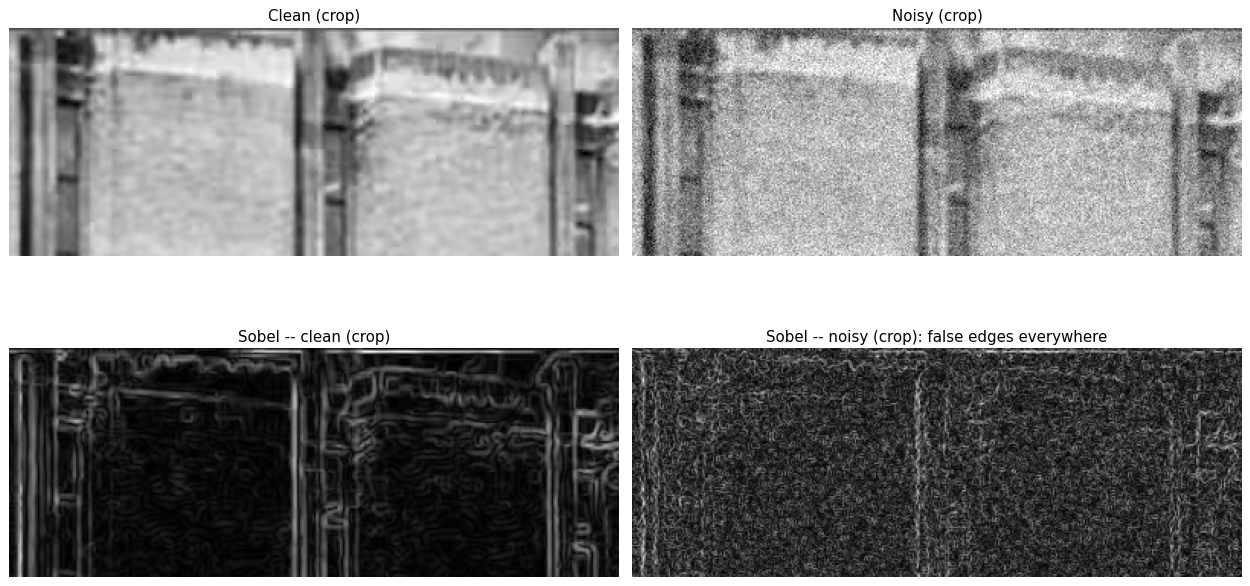

In [ ]:
# Crop a flat-ish region (sky/wall area, top-left) to show noise-induced false edges clearly
y0, y1, x0, x1 = 0, 150, 600, 1000

fig, axs = plt.subplots(2, 2, figsize=(14, 8))
axs[0,0].imshow(img_gray[y0:y1, x0:x1], cmap='gray');  axs[0,0].set_title("Clean (crop)")
axs[0,1].imshow(img_noisy[y0:y1, x0:x1], cmap='gray'); axs[0,1].set_title("Noisy (crop)")
axs[1,0].imshow(mag_clean[y0:y1, x0:x1], cmap='gray'); axs[1,0].set_title("Sobel -- clean (crop)")
axs[1,1].imshow(mag_noisy[y0:y1, x0:x1], cmap='gray'); axs[1,1].set_title("Sobel -- noisy (crop): false edges everywhere")
for r in axs:
    for a in r:
        a.axis('off')
plt.tight_layout()
plt.show()

---
## 6. The Role of Smoothing, and Preserving Weak Edges Without Excess Noise

### 6.1 Why smooth before differentiating?

Because differentiation amplifies high-frequency noise, the standard remedy is to **low-pass
filter (smooth) the image first**, then differentiate. A Gaussian blur is the natural choice: it
suppresses high-frequency noise while disturbing low-frequency structure (the large-scale shapes
that define real edges) comparatively little. This is the same principle already built into the
Sobel kernel itself at a $3\times3$ scale (Section 1.3) -- pre-smoothing with a larger Gaussian
extends that noise-suppression to a wider neighbourhood, which matters when the noise level is
high relative to the kernel's built-in averaging.

We compare the effect of Gaussian smoothing (`scipy.ndimage.gaussian_filter`) applied to the noisy
image *before* running the Sobel operator, against running Sobel directly on the unsmoothed noisy
image.

Gradient magnitude std -- clean: 68.09, noisy: 76.19, smoothed-then-edge: 48.22


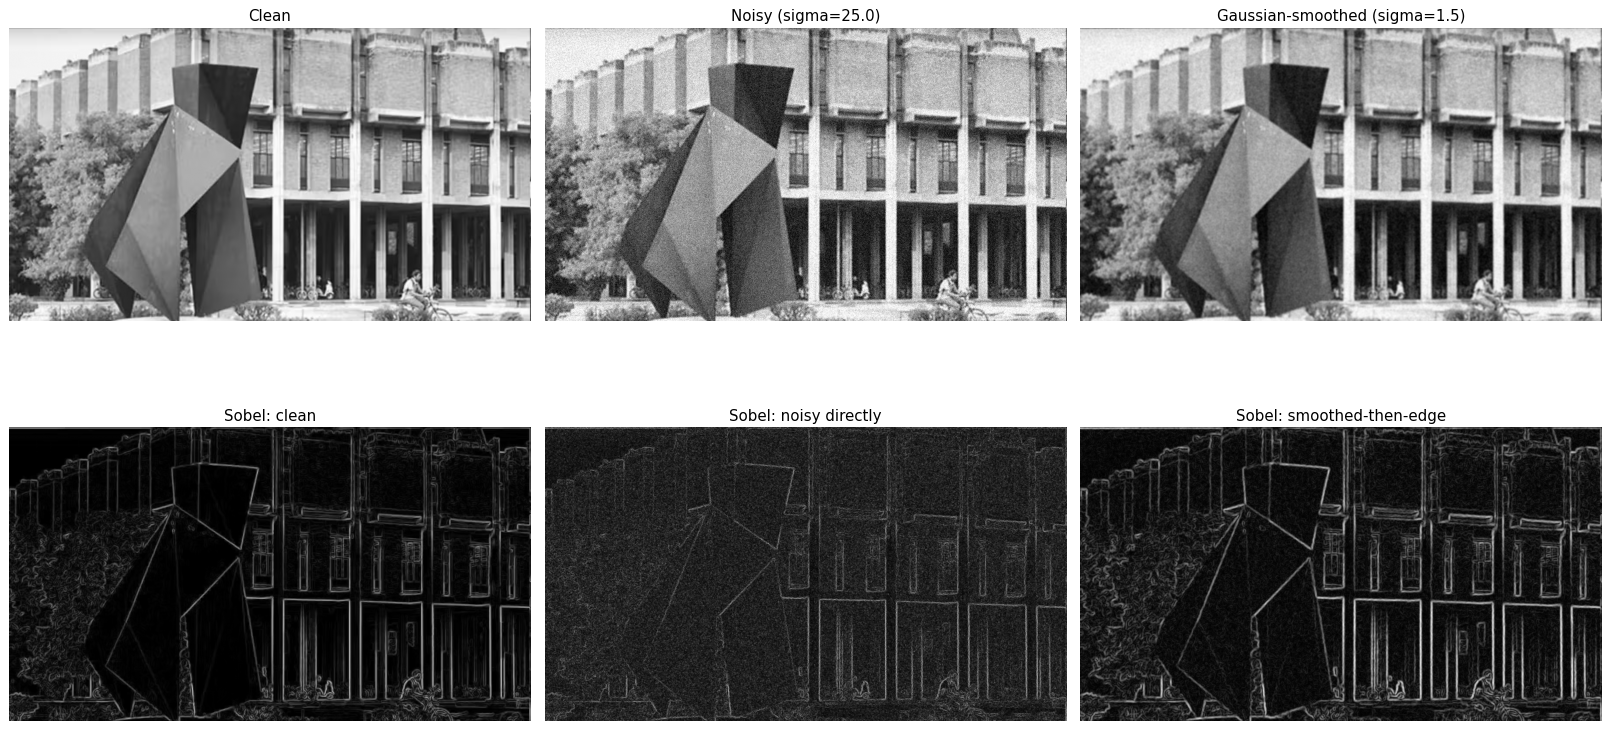

In [ ]:
smoothing_sigma = 1.5
img_smoothed = ndimage.gaussian_filter(img_noisy, sigma=smoothing_sigma)
_, _, mag_smoothed, _ = sobel_filter(img_smoothed)

fig, axs = plt.subplots(2, 3, figsize=(18, 10))

axs[0,0].imshow(img_gray, cmap='gray');     axs[0,0].set_title("Clean")
axs[0,1].imshow(img_noisy, cmap='gray');    axs[0,1].set_title(f"Noisy (sigma={noise_sigma})")
axs[0,2].imshow(img_smoothed, cmap='gray'); axs[0,2].set_title(f"Gaussian-smoothed (sigma={smoothing_sigma})")

axs[1,0].imshow(mag_clean, cmap='gray');    axs[1,0].set_title("Sobel: clean")
axs[1,1].imshow(mag_noisy, cmap='gray');    axs[1,1].set_title("Sobel: noisy directly")
axs[1,2].imshow(mag_smoothed, cmap='gray'); axs[1,2].set_title("Sobel: smoothed-then-edge")

for r in axs:
    for a in r:
        a.axis('off')
plt.tight_layout()
plt.show()

print(f"Gradient magnitude std -- clean: {mag_clean.std():.2f}, noisy: {mag_noisy.std():.2f}, "
      f"smoothed-then-edge: {mag_smoothed.std():.2f}")

Pre-smoothing visibly removes the speckled false-edge noise from Section 5 and recovers a
gradient map much closer to the clean result. This confirms the **smooth-then-differentiate**
strategy (which is, not coincidentally, also the principle behind the more advanced Canny edge
detector, which Gaussian-blurs before applying Sobel-like gradients).

### 6.2 The cost of smoothing: blurred and lost weak edges

Smoothing is not free. A Gaussian blur is a *low-pass filter regardless of whether the
high-frequency content it removes is noise or a genuine fine edge*. Thin or low-contrast
structures -- a hairline crack, distant railings, fine texture -- occupy the same high-frequency
band as noise, so aggressive smoothing risks erasing them along with the noise. We illustrate this
trade-off with a sweep over the smoothing strength $\sigma$.

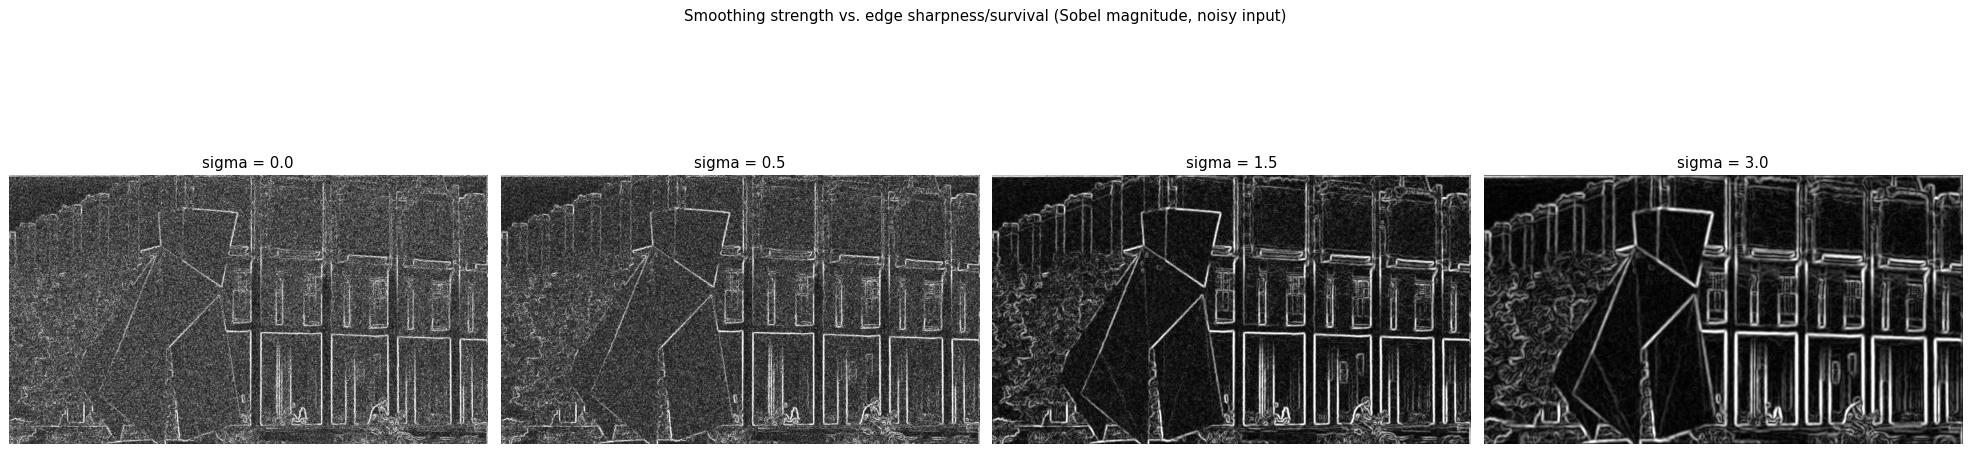

In [ ]:
sigmas_to_test = [0.0, 0.5, 1.5, 3.0]

fig, axs = plt.subplots(1, len(sigmas_to_test), figsize=(22, 6))
for ax, s in zip(axs, sigmas_to_test):
    blurred = ndimage.gaussian_filter(img_noisy, sigma=s) if s > 0 else img_noisy
    _, _, mag_s, _ = sobel_filter(blurred)
    ax.imshow(mag_s, cmap='gray', vmax=np.percentile(mag_s, 99))
    ax.set_title(f"sigma = {s}")
    ax.axis('off')
plt.suptitle("Smoothing strength vs. edge sharpness/survival (Sobel magnitude, noisy input)", y=1.03)
plt.tight_layout()
plt.show()

**Reading the sweep, left to right:**
- $\sigma=0$ (no smoothing): edges are sharp but drowned in noise speckle, matching Section 5.
- $\sigma=0.5$: noise is only mildly reduced -- still quite speckled.
- $\sigma=1.5$: a good operating point -- most noise speckle is gone, the building's grid, the
  sculpture's facets, and finer details like the window mullions and bicycle remain visible.
- $\sigma=3.0$: noise is essentially eliminated, but fine structures (individual window mullions,
  thin railings, the cyclist's outline) have visibly thinned, faded, or merged into neighbouring
  edges. Some genuinely weak-but-real edges are lost.

This is a direct illustration of the **noise-suppression vs. detail-preservation trade-off**: there
is no single $\sigma$ that is simultaneously "maximally clean" and "maximally detail-preserving" --
the right choice depends on the noise level and on how much fine detail matters for the
downstream task.

### 6.3 Can weak edges be preserved without re-introducing excessive noise?

Yes -- the key idea is to **decouple detection from connectivity**. Rather than relying on a single
global magnitude threshold (which forces a binary choice: a pixel is either "edge" or "not edge"
based purely on its own strength), we use **double (hysteresis) thresholding**, the same principle
Canny's edge detector is built on:

1. Pixels with gradient magnitude above a **high** threshold are immediately accepted as
   *strong* edges (these are almost certainly real).
2. Pixels with magnitude between a **low** and **high** threshold are marked as *weak* candidates.
3. A weak pixel is **kept only if it is spatially connected** (8-connectivity) to a strong edge
   pixel; isolated weak pixels (typically noise) are discarded.

This preserves *legitimate* faint edges -- which tend to form a continuous chain connected to a
stronger part of the same boundary -- while rejecting *isolated* weak responses, which are the
hallmark of noise.

In [ ]:
mag_for_threshold = mag_smoothed / mag_smoothed.max() * 255  # normalise to 0-255

low_pct, high_pct = 80, 95
low_thresh  = np.percentile(mag_for_threshold, low_pct)
high_thresh = np.percentile(mag_for_threshold, high_pct)
print(f"Low threshold (p{low_pct}) : {low_thresh:.2f}")
print(f"High threshold (p{high_pct}): {high_thresh:.2f}")

strong_mask = mag_for_threshold >= high_thresh
weak_mask   = (mag_for_threshold >= low_thresh) & (mag_for_threshold < high_thresh)

# 8-connected component labelling over (strong OR weak) pixels
structure = np.ones((3, 3))
labeled, n_components = ndimage.label(strong_mask | weak_mask, structure=structure)

# keep only components that contain at least one strong pixel
labels_touching_strong = set(np.unique(labeled[strong_mask]))
labels_touching_strong.discard(0)  # 0 = background
hysteresis_mask = np.isin(labeled, list(labels_touching_strong))

print(f"Connected components found: {n_components}, kept (touch a strong edge): "
      f"{len(labels_touching_strong)}")

Low threshold (p80) : 44.82
High threshold (p95): 98.88
Connected components found: 1627, kept (touch a strong edge): 89


Edge pixel count -- strong only: 40500, naive low threshold: 162000, hysteresis: 137919


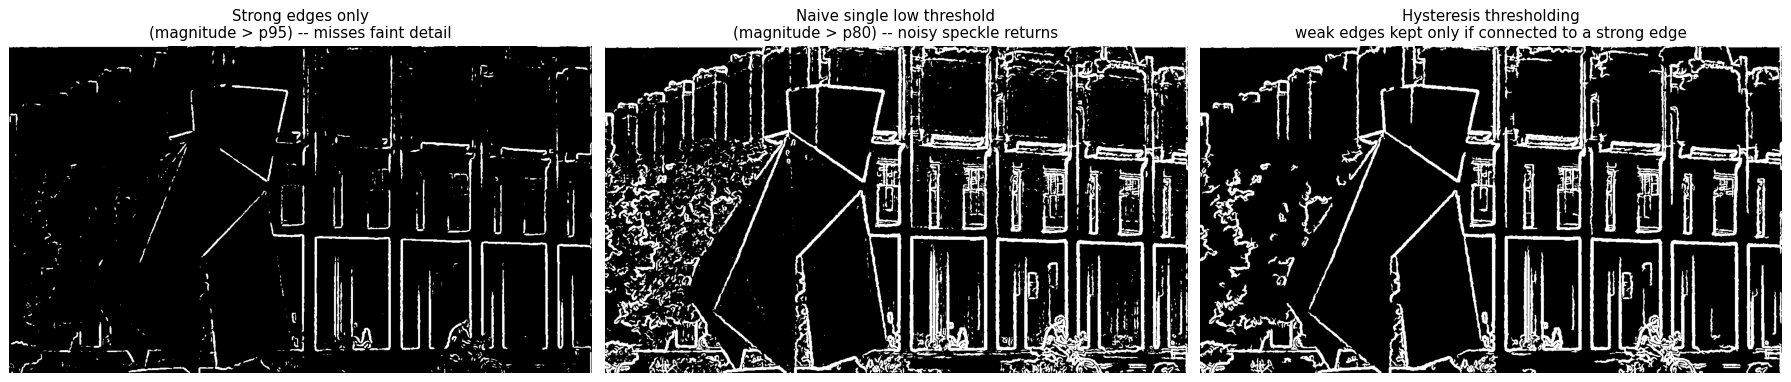

In [ ]:
naive_mask = mag_for_threshold >= low_thresh  # naive single low threshold: keeps ALL weak pixels too

fig, axs = plt.subplots(1, 3, figsize=(20, 7))
axs[0].imshow(strong_mask, cmap='gray')
axs[0].set_title(f"Strong edges only\n(magnitude > p{high_pct}) -- misses faint detail")

axs[1].imshow(naive_mask, cmap='gray')
axs[1].set_title(f"Naive single low threshold\n(magnitude > p{low_pct}) -- noisy speckle returns")

axs[2].imshow(hysteresis_mask, cmap='gray')
axs[2].set_title("Hysteresis thresholding\nweak edges kept only if connected to a strong edge")

for a in axs:
    a.axis('off')
plt.tight_layout()
plt.show()

n_pixels_strong_only = strong_mask.sum()
n_pixels_naive = naive_mask.sum()
n_pixels_hysteresis = hysteresis_mask.sum()
print(f"Edge pixel count -- strong only: {n_pixels_strong_only}, naive low threshold: "
      f"{n_pixels_naive}, hysteresis: {n_pixels_hysteresis}")

**Result.** The hysteresis mask sits between the two extremes: it recovers visibly more of the
faint structure than the strong-only threshold (extra window mullions, fainter sculpture facet
lines reappear), while avoiding most of the scattered isolated speckle that floods the naive
single-low-threshold mask. The pixel counts above quantify this: hysteresis keeps noticeably more
pixels than "strong only" (weak-but-connected edges are recovered) yet noticeably fewer than the
naive threshold (isolated noise is rejected).

So: **yes, weak edges can be preserved without admitting excessive noise** -- not by lowering a
single global threshold (which preserves weak edges *and* noise indiscriminately, since both
produce low-to-moderate gradient magnitude), but by using **spatial context**: genuine edges form
connected chains, while noise-induced gradient responses are spatially incoherent. Combined with
modest pre-smoothing (Section 6.1-6.2) to deal with the noise at its source, hysteresis
thresholding gives a principled way to recover faint real structure that a single hard threshold
would otherwise discard.


---
## 7. Summary

| Question asked | Answer (with evidence from this notebook) |
|---|---|
| Mathematical operation to find rapid-intensity-change regions | The **derivative / gradient** $\nabla I$; large $\|\nabla I\|$ marks an edge (Section 1.1) |
| Relation between derivatives, gradients, and edge detection | Edges are local maxima of gradient magnitude; gradient direction gives edge orientation (Section 1.1, 4) |
| What is the Sobel filter | A $3\times3$ kernel pair combining central-difference differentiation with built-in smoothing, approximating $\partial I/\partial x$ and $\partial I/\partial y$ (Section 1.3) |
| How 2-D convolution applies it | Kernel slid over the image, each output pixel a weighted sum of its neighbourhood (Section 1.4, 3.2-3.4) |
| Effect of noise on detected boundaries | Noise creates widespread spurious gradient responses ("speckle"), raising the background gradient level and obscuring true edges (Section 5) |
| Role of smoothing before edge extraction | Low-pass filtering removes high-frequency noise before differentiation amplifies it, at the cost of blurring/losing the finest real detail (Section 6.1-6.2) |
| Preserving weak edges without excess noise | Hysteresis (double) thresholding: accept high-confidence strong edges outright, and accept weak edges only when spatially connected to a strong edge, exploiting the fact that real edges are spatially coherent while noise is not (Section 6.3) |

**Overall pipeline recommended for this image:** grayscale conversion $\to$ mild Gaussian smoothing
($\sigma\approx1$-$1.5$, tuned to the noise level) $\to$ Sobel gradient computation $\to$ hysteresis
thresholding. This recovers the structural "wireframe" of the scene -- matching the style of output
shown in Figure 1 of the question -- while remaining robust to sensor/compression noise and without
sacrificing genuinely faint boundaries.